<a href="https://colab.research.google.com/github/Agouillal-Mayes/object-recognition-neural-network/blob/main/object_recogn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
!pip install -q kagglehub

import kagglehub
import os
from tensorflow import keras

# 1. Télécharger Caltech-256 depuis Kaggle (environ 500 Mo)
path = kagglehub.dataset_download("jessicali9530/caltech256")

print("Dataset téléchargé dans :", path)

# Le sous-dossier contenant les catégories d'objets
data_dir = os.path.join(path, "256_ObjectCategories")

# 2. Charger directement dans Keras avec la taille 224x224 pour ResNet
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"  # Crée des entiers de 0 à 256
)

val_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

print(f"Nombre de classes trouvées : {len(train_ds.class_names)}")

100%|██████████| 2.12G/2.12G [00:41<00:00, 54.3MB/s]

Extracting files...


Dataset téléchargé dans : /root/.cache/kagglehub/datasets/jessicali9530/caltech256/versions/2
Found 30607 files belonging to 257 classes.
Using 24486 files for training.
Found 30607 files belonging to 257 classes.
Using 6121 files for validation.
Nombre de classes trouvées : 257


Aperçu des classes d'objets :
• ak47
• american-flag
• backpack
• baseball-bat
• baseball-glove
• basketball-hoop
• bat
• bathtub
• bear
• beer-mug


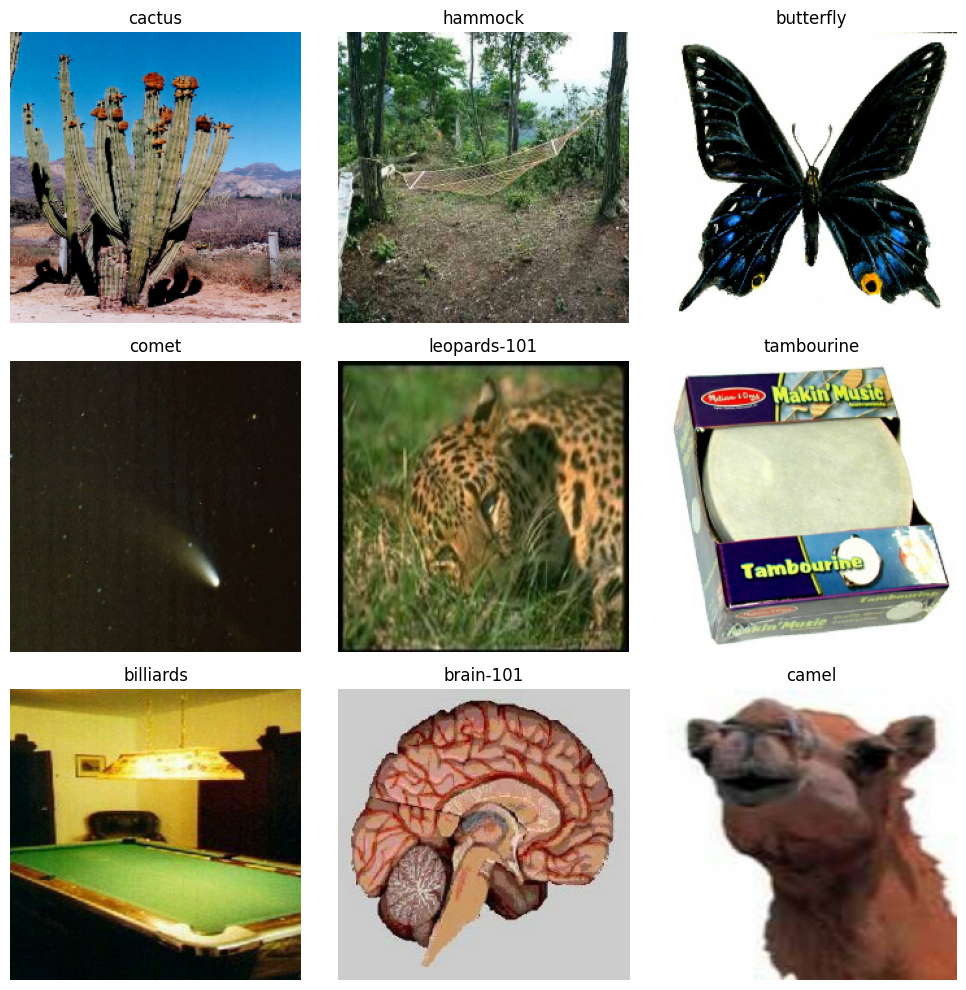

In [31]:
import matplotlib.pyplot as plt

# Afficher les 10 premières classes chargées (tu verras des véhicules, instruments, objets)
print("Aperçu des classes d'objets :")
for name in train_ds.class_names[:10]:
    # On retire le numéro de synset devant le nom (ex: "001.ak47" -> "ak47")
    clean_name = name.split(".")[1] if "." in name else name
    print(f"• {clean_name}")

# Affichage visuel d'un batch
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        raw_title = train_ds.class_names[labels[i]]
        clean_title = raw_title.split(".")[1] if "." in raw_title else raw_title
        plt.title(clean_title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

print("ANALYSE TECHNIQUE DU DATASET CALTECH-256")
print(f"Nombre de classes détectées : {len(train_ds.class_names)}")

# 1. Inspection de la structure des Tensors sur un batch
for images, labels in train_ds.take(1):
    print(f"\nFORMAT DES DONNÉES")
    print(f"Forme du batch d'images (N, H, W, C) : {images.shape}")
    print(f"Forme du batch de labels : {labels.shape}")
    print(f"Type de données des images : {images.dtype}")
    print(f"Type de données des images : {images.dtype}")
    print(f"Type de données des labels : {labels.dtype}")
    print(f"Plage de valeurs des pixels : min = {images.numpy().min():.1f}, max = {images.numpy().max():.1f}")
    print(f"Exemple de labels dans le batch : {labels.numpy()[:10]}")

# 2. Volumes d'entraînement et de validation
num_train_batches = tf.data.experimental.cardinality(train_ds).numpy()
num_val_batches = tf.data.experimental.cardinality(val_ds).numpy()

print(f"\nVOLUMÉTRIE")
print(f"Batches d'Entraînement : {num_train_batches} (~{num_train_batches * BATCH_SIZE} images)")
print(f"Batches de Validation  : {num_val_batches} (~{num_val_batches * BATCH_SIZE} images)")

# 3. Aperçu des 10 premières catégories d'objets chargées
print(f"\n--- ÉCHANTILLON DES CLASSES D'OBJETS ---")
for idx, full_name in enumerate(train_ds.class_names[:10]):
    clean_name = full_name.split(".")[1] if "." in full_name else full_name
    print(f"  [{idx:3d}] -> {clean_name}")

ANALYSE TECHNIQUE DU DATASET CALTECH-256
Nombre de classes détectées : 257

FORMAT DES DONNÉES
Forme du batch d'images (N, H, W, C) : (32, 224, 224, 3)
Forme du batch de labels : (32,)
Type de données des images : <dtype: 'float32'>
Type de données des images : <dtype: 'float32'>
Type de données des labels : <dtype: 'int32'>
Plage de valeurs des pixels : min = 0.0, max = 255.0
Exemple de labels dans le batch : [149 169 122 144 127  29  61  64 114 202]

VOLUMÉTRIE
Batches d'Entraînement : 766 (~24512 images)
Batches de Validation  : 192 (~6144 images)

--- ÉCHANTILLON DES CLASSES D'OBJETS ---
  [  0] -> ak47
  [  1] -> american-flag
  [  2] -> backpack
  [  3] -> baseball-bat
  [  4] -> baseball-glove
  [  5] -> basketball-hoop
  [  6] -> bat
  [  7] -> bathtub
  [  8] -> bear
  [  9] -> beer-mug


In [35]:
# Extract, clean, and format all class names
class_names = train_ds.class_names

print(f"Total classes found: {len(class_names)}\n")
print("=" * 60)
print(f"{'INDEX':<7} | {'FOLDER NAME':<20} | {'CLEAN NAME'}")
print("=" * 60)

for idx, name in enumerate(class_names):
    # Separate category ID prefix from actual object name
    clean_name = name.split(".")[1] if "." in name else name
    print(f"[{idx:3d}]   | {name:<20} | {clean_name}")

Total classes found: 257

INDEX   | FOLDER NAME          | CLEAN NAME
[  0]   | 001.ak47             | ak47
[  1]   | 002.american-flag    | american-flag
[  2]   | 003.backpack         | backpack
[  3]   | 004.baseball-bat     | baseball-bat
[  4]   | 005.baseball-glove   | baseball-glove
[  5]   | 006.basketball-hoop  | basketball-hoop
[  6]   | 007.bat              | bat
[  7]   | 008.bathtub          | bathtub
[  8]   | 009.bear             | bear
[  9]   | 010.beer-mug         | beer-mug
[ 10]   | 011.billiards        | billiards
[ 11]   | 012.binoculars       | binoculars
[ 12]   | 013.birdbath         | birdbath
[ 13]   | 014.blimp            | blimp
[ 14]   | 015.bonsai-101       | bonsai-101
[ 15]   | 016.boom-box         | boom-box
[ 16]   | 017.bowling-ball     | bowling-ball
[ 17]   | 018.bowling-pin      | bowling-pin
[ 18]   | 019.boxing-glove     | boxing-glove
[ 19]   | 020.brain-101        | brain-101
[ 20]   | 021.breadmaker       | breadmaker
[ 21]   | 022.buddha-101

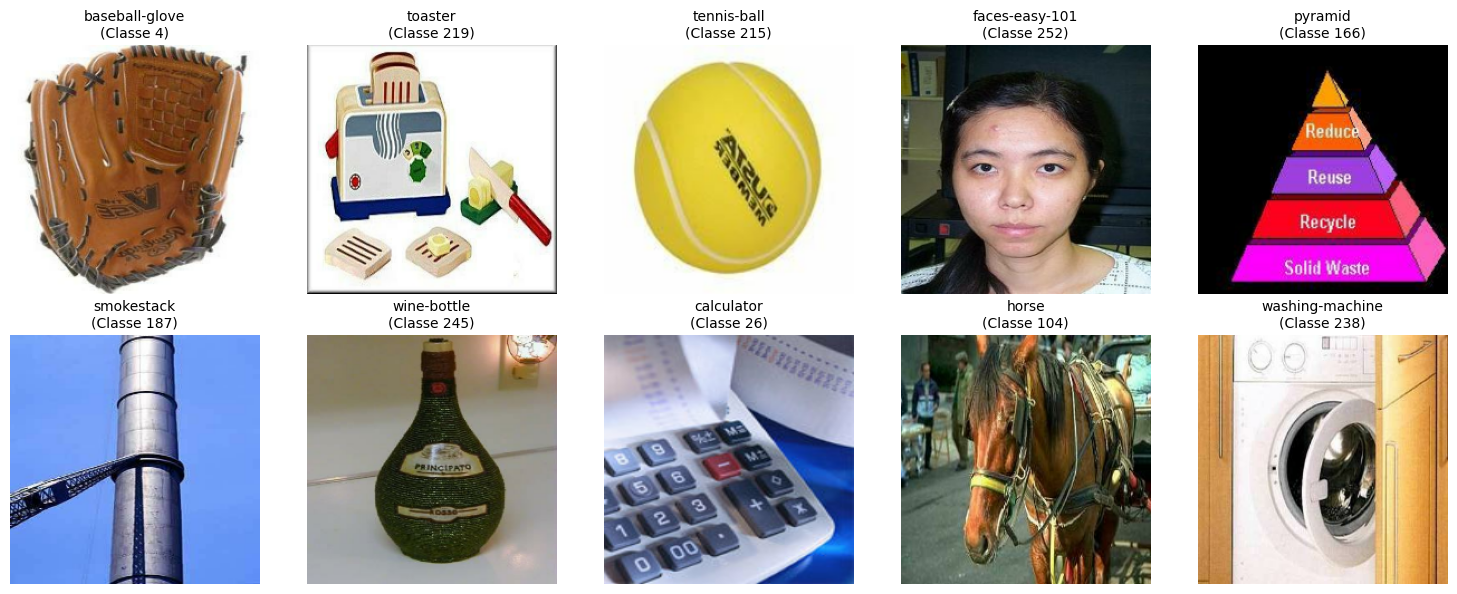

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# 1. Prendre un batch d'images
for images, labels in train_ds.take(1):
    batch_size = images.shape[0]

    # 2. Tirer 10 indices au hasard dans le batch
    random_indices = np.random.choice(batch_size, size=min(10, batch_size), replace=False)

    plt.figure(figsize=(15, 6))

    # 3. Afficher les 10 images dans une grille 2x5
    for plot_idx, img_idx in enumerate(random_indices):
        plt.subplot(2, 5, plot_idx + 1)

        # Affichage de l'image (format uint8 pour Matplotlib)
        plt.imshow(images[img_idx].numpy().astype("uint8"))

        # Récupération et nettoyage du nom de classe
        raw_label = train_ds.class_names[labels[img_idx]]
        clean_label = raw_label.split(".")[1] if "." in raw_label else raw_label

        plt.title(f"{clean_label}\n(Classe {labels[img_idx].numpy()})", fontsize=10)
        plt.axis("off")

    plt.tight_layout()
    plt.show()
    break

In [42]:
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    # 1. Flip horizontal uniquement (conserve le sens naturel des objets)
    tf.keras.layers.RandomFlip("horizontal"),

    # 2. Rotation légère (-20% à +20%)
    tf.keras.layers.RandomRotation(factor=0.2, fill_mode="reflect"),

    # 3. Zoom (-20% à +20%)
    tf.keras.layers.RandomZoom(height_factor=0.2, width_factor=0.2, fill_mode="reflect"),

    # 4. Translation (-20% à +20%)
    tf.keras.layers.RandomTranslation(height_factor=0.2, width_factor=0.2, fill_mode="reflect"),

    # 5. Variations de contraste et de luminosité (adaptées à la plage 0-255)
    tf.keras.layers.RandomContrast(factor=0.2),
    tf.keras.layers.RandomBrightness(factor=0.2, value_range=(0, 255)),

    # 6. Ajout de bruit gaussien léger
    tf.keras.layers.GaussianNoise(0.05)
], name="data_augmentation")

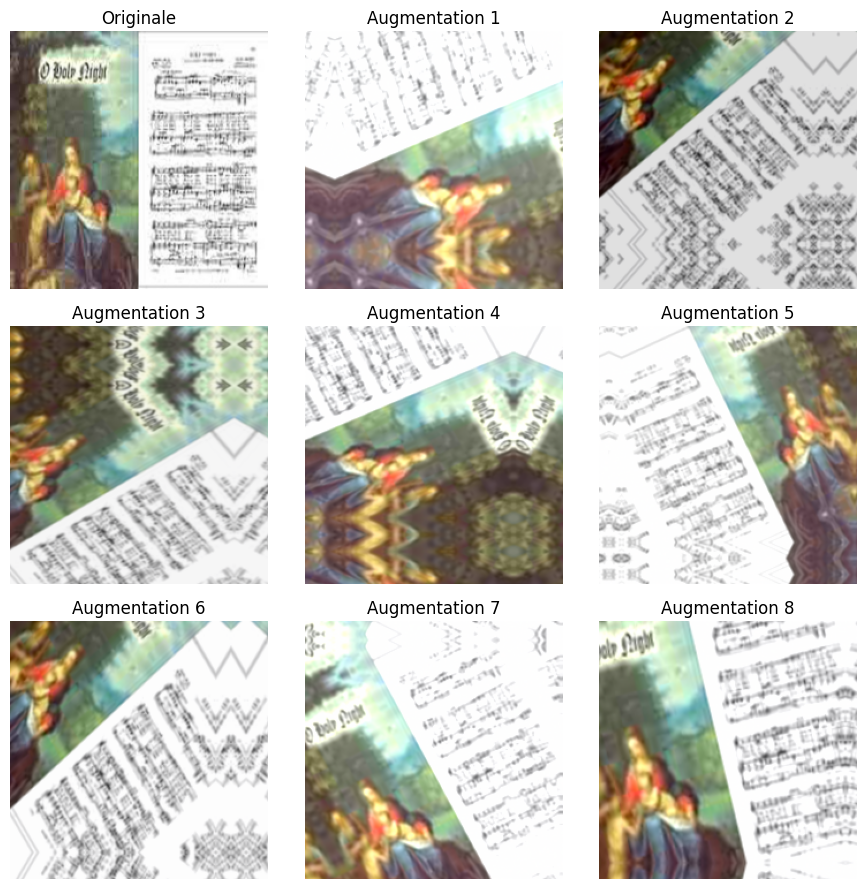

In [44]:
import matplotlib.pyplot as plt

# Prendre la première image du batch
for images, _ in train_ds.take(1):
    sample_img = images[0]
    break

plt.figure(figsize=(9, 9))
plt.subplot(3, 3, 1)
plt.imshow(sample_img.numpy().astype("uint8"))
plt.title("Originale")
plt.axis("off")

# Générer 8 augmentations de la même image
for i in range(2, 10):
    augmented_img = data_augmentation(tf.expand_dims(sample_img, 0), training=True)
    plt.subplot(3, 3, i)
    plt.imshow(augmented_img[0].numpy().astype("uint8"))
    plt.title(f"Augmentation {i-1}")
    plt.axis("off")

plt.tight_layout()
plt.show()